# Calibration on the dipole

The gain of a detector is rarely known to better than a percent, and it
drifts. {class}`~pysanepic.CalibrationParameters` fits it together with the
maps, using the dipole as calibrator: the TOD is modeled as
$d = g\,(P m + D) + n$, with $D$ the dipole signal of each sample
(`DetectorData.dipole`) and one gain $g$ per detector and period
(`gain_period_s`). Around the current gains the model is linear,

$$d/g - D = P m + T\,\delta g + n, \qquad T = D + P m_\text{prev},$$

and the PCG solves for the map and the gain corrections $\delta g$ at once;
then $g \leftarrow g\,(1 + \delta g)$ and again, `n_iter` times. A gain common
to all periods would rescale the map as well, so it is fixed by the part of
$D$ that is not a sky signal: the **orbital** dipole, which changes direction
over the year. The solar dipole, fixed on the sky, calibrates the relative
gains between periods and detectors.

Here: 4 detectors in two orthogonal pairs, a compressed "year" of 6.7 hours
(the orbital velocity turns once), 1/f noise, gains with a 1% offset and a
3% random walk. The sky is a CMB at the map resolution (nside 16) plus a bright
Galactic band, 3 mK in I, with structure below the pixel size (simulated at
nside 128), as real foregrounds have.

In [1]:
import dataclasses

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from pysanepic import CalibrationParameters, DetectorData, GLSParameters, OneOverFNoise, Pointing, make_maps

nside, fs, n = 16, 10.0, 240_000
rng = np.random.default_rng(3)
npix = 12 * nside**2
z = hp.pix2vec(nside, np.arange(npix))[2]
cmb = hp.smoothing(rng.normal(0, 1e-4, (3, npix)), fwhm=np.radians(6))
hi = 128  # the Galaxy below the pixel size
zh = hp.pix2vec(hi, np.arange(12 * hi**2))[2]
galaxy = np.where(np.abs(zh) < 0.2, 3e-3 * (1 + hp.smoothing(rng.normal(0, 0.3, 12 * hi**2), fwhm=np.radians(1))), 0.0)
sky = cmb.copy()
sky[0] += hp.ud_grade(galaxy, nside)  # what the maps can see: the average in each pixel
noise = OneOverFNoise(net_ukrts=35.0, fknee_hz=0.05, alpha=1.0, fmin_hz=1e-4)

t = np.arange(n)
lam = 2 * np.pi * t / n + rng.uniform(0, 2 * np.pi)  # anti-Sun direction, one turn = the "year"
spin = 2 * np.pi * t / 3000.0
a = np.array([np.cos(lam), np.sin(lam), np.zeros(n)])
e2 = np.cross(a.T, [0, 0, 1]).T
vec = np.cos(1.3) * a + np.sin(1.3) * (np.cos(spin) * np.array([[0], [0], [1]]) + np.sin(spin) * e2)
theta, phi = np.arccos(np.clip(vec[2], -1, 1)), np.arctan2(vec[1], vec[0]) % (2 * np.pi)
psi = (spin + lam) % (2 * np.pi) - np.pi

solar = 3.36e-3 * np.array([0.3, -0.5, 0.8]) / np.linalg.norm([0.3, -0.5, 0.8])
orbital = 2.7e-4 * np.array([-np.sin(lam), np.cos(lam), 0 * t])  # 30 km/s, perpendicular to the Sun direction
dipole = solar @ vec + np.sum(orbital * vec, axis=0)  # K


def draw(n):
    return np.fft.irfft(np.fft.rfft(rng.normal(size=n)) / np.sqrt(noise.weights(n, fs)), n=n)


p, ph = hp.ang2pix(nside, theta, phi), hp.ang2pix(hi, theta, phi)
data, true_gain = [], []
for i, pol_angle in enumerate(np.radians([0, 90, 45, 135])):
    ang = psi + pol_angle
    signal = cmb[0, p] + galaxy[ph] + cmb[1, p] * np.cos(2 * ang) + cmb[2, p] * np.sin(2 * ang) + dipole
    g = 1 + 0.01 * rng.normal() + 0.03 * np.cumsum(rng.normal(size=n)) / np.sqrt(n)
    true_gain.append(g)
    data.append(DetectorData(tod=g * signal + draw(n), pointing=Pointing(theta=theta, phi=phi, psi=psi, coordinates="E"),
                             sampling_rate_hz=fs, noise=noise, pol_angle_rad=pol_angle, dipole=dipole, name=f"d{i}"))
params = GLSParameters(chunk_s=2400.0, tol=1e-12)
band = np.abs(z) < 0.3  # the Galactic band, with a margin

Two references: the maps with the true gains, and with the gains taken as 1
(the dipole subtracted). The errors are the rms of map minus sky, in µK,
outside the Galactic band; the gain errors are the rms of $g/g_\text{true} - 1$
over all samples, and its mean (the error on the absolute calibration).

In [2]:
def report(name, r, period_s=None):
    seen = (r.maps[1] != hp.UNSEEN) & ~band
    err = (r.maps - sky)[:, seen] * 1e6
    line = f"{name:34s} map I/Q/U {err[0].std():6.2f} / {err[1].std():6.2f} / {err[2].std():6.2f} uK"
    if period_s is not None:
        per = int(period_s * fs) if np.isfinite(period_s) else n
        e = np.array([g[t // per] / g0 - 1 for g, g0 in zip(r.gains, true_gain)])
        line += f"   gain error rms {np.sqrt(np.mean(e**2)):.1e}, absolute {e.mean():+.1e}"
    print(line)


report("true gains", make_maps([dataclasses.replace(d, tod=d.tod / g - dipole) for d, g in zip(data, true_gain)],
                               nside, coordinates="E", params=params))
report("gains = 1", make_maps([dataclasses.replace(d, tod=d.tod - dipole) for d in data], nside, coordinates="E", params=params))

true gains                         map I/Q/U  13.08 /  12.45 /  12.79 uK


gains = 1                          map I/Q/U  27.71 /  15.62 /  15.23 uK


## Mask

Calibrating on all the samples, the absolute calibration is off by 2% and the
I map is worse than with no calibration at all: the structure of the Galaxy
below the pixel size is not in the model, and through the 1/f weights it
leaks into the large scales of the map and into the gains. With `mask`, the samples in the masked pixels are left out of the
calibration iterations (as flagged samples), and one more GLS solve makes the
maps with all the samples and the final gains.

In [3]:
for mask in (None, ~band):  # masks: 1 = used, 0 = left out
    r = make_maps(data, nside, coordinates="E", params=params, calibration=CalibrationParameters(gain_period_s=1200.0, mask=mask))
    report("calibrated, " + ("mask" if mask is not None else "no mask"), r, 1200.0)

calibrated, no mask                map I/Q/U  49.22 /  12.19 /  12.54 uK   gain error rms 2.5e-02, absolute +2.4e-02


calibrated, mask                   map I/Q/U  13.21 /  12.47 /  12.75 uK   gain error rms 3.5e-03, absolute +8.5e-04


With the mask the maps are as good as with the true gains. The masked
samples are flagged with `GLSParameters.flag_method`: `"offset"` (one unknown
per run of masked samples) costs no memory and gives the same gains as
`"marginalize"` here.

## Iterations

The first iteration has no sky in the template ($T = D$, or $D + S$ with
a `sky_model` $S$ given to `make_maps`), from the second one the map of the
previous iteration. The sky enters only multiplied by $\delta g$, and outside the
mask it is much fainter than the dipole: here one iteration is already as good
as three. The noiseless tests show how fast the iterations converge when
nothing else limits them: gain errors $3\times10^{-4} \to 3\times10^{-8} \to
5\times10^{-15}$. The default is 2.

In [4]:
for n_iter in (1, 2, 3):
    r = make_maps(data, nside, coordinates="E", params=params,
                  calibration=CalibrationParameters(gain_period_s=1200.0, mask=~band, n_iter=n_iter))
    report(f"n_iter = {n_iter}", r, 1200.0)
cal = r

n_iter = 1                         map I/Q/U  13.21 /  12.46 /  12.74 uK   gain error rms 3.5e-03, absolute +8.4e-04


n_iter = 2                         map I/Q/U  13.21 /  12.47 /  12.75 uK   gain error rms 3.5e-03, absolute +8.5e-04


n_iter = 3                         map I/Q/U  13.21 /  12.47 /  12.75 uK   gain error rms 3.5e-03, absolute +8.4e-04


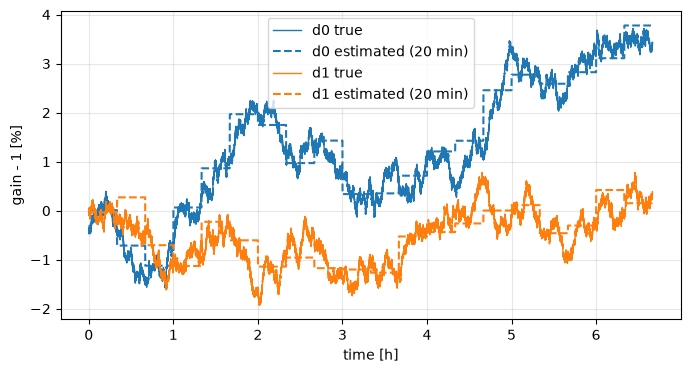

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
hours = t / fs / 3600
for i in (0, 1):
    ax.plot(hours, (true_gain[i] - 1) * 100, f"C{i}", lw=1, label=f"d{i} true")
    ax.plot(hours, (cal.gains[i][t // 12000] - 1) * 100, f"C{i}--", label=f"d{i} estimated (20 min)")
ax.set_xlabel("time [h]")
ax.set_ylabel("gain - 1 [%]")
ax.legend()
ax.grid(alpha=0.3)

## Gain period

Short periods follow the drift but each gain has fewer samples, hence more
noise; long ones average the noise but not the drift. Here the optimum is
between 5 and 20 minutes; with a real drift model it is worth repeating this
scan.

In [6]:
for period in (300.0, 600.0, 1200.0, 2400.0, 6000.0, np.inf):
    r = make_maps(data, nside, coordinates="E", params=params,
                  calibration=CalibrationParameters(gain_period_s=period, mask=~band, n_iter=2))
    report(f"gain_period_s = {period:g}", r, period)

gain_period_s = 300                map I/Q/U  13.19 /  12.42 /  12.71 uK   gain error rms 3.9e-03, absolute +7.6e-04


gain_period_s = 600                map I/Q/U  13.20 /  12.42 /  12.74 uK   gain error rms 3.5e-03, absolute +7.8e-04


gain_period_s = 1200               map I/Q/U  13.21 /  12.47 /  12.75 uK   gain error rms 3.5e-03, absolute +8.5e-04


gain_period_s = 2400               map I/Q/U  13.26 /  12.51 /  12.87 uK   gain error rms 4.1e-03, absolute +8.5e-04


gain_period_s = 6000               map I/Q/U  13.81 /  12.89 /  12.97 uK   gain error rms 6.2e-03, absolute +2.0e-03


gain_period_s = inf                map I/Q/U  17.06 /  13.80 /  13.72 uK   gain error rms 1.5e-02, absolute -4.7e-03


## Notes

- Only $D$ is subtracted from the data. To keep the solar dipole in the maps,
  calibrate with $D$ = solar + orbital and add the solar dipole map back to
  the result; $D$ must contain the
  orbital dipole, which sets the absolute calibration.
- `make_maps(sky_model=...)`: a sky model, which is also in the template;
  given as alm it removes the structure below the pixel size, so the Galaxy
  needs no mask, and templates (`Template(sky=...)`) fit the foregrounds seen through
  different bands (see the sky model notebook).
- Each iteration is a full GLS solve (plus one with a mask); the gains are
  unknowns local to the MPI process of their detector, so calibration adds no
  communication.
- Low level: `GLS(templates=[(chunk, values, labels), ...])` fits any template
  amplitudes with the map; `info["amplitudes"]` returns them.